## Diffusion Model

### 0. Data

In [ ]:
import pandas as pd

url = "http://byungwan.com/class/Subs.xlsx"
internet = pd.read_excel(url)

internet.head()

In [ ]:
internet["Year"] = pd.to_datetime(internet["Year"], format="%Y").dt.year 
#Now, Python recognizes the year as year (time series)

internet.head()

In [ ]:
internet = internet.set_index("Year")

internet.head()

### 1. Diffusion Model

In [ ]:
from statsmodels.formula import api as smf
import numpy as np

internet["Lag_Cum_Subs"] = internet["Cum_Subs"].shift(1)

internet.head()

In [ ]:
reg = smf.ols(formula = "Subs ~ Lag_Cum_Subs + np.power(Lag_Cum_Subs, 2)", data = internet).fit()
print(reg.summary())

In [ ]:
reg.params

#respectively, alpha 0 (intercept), alpha 1 (Leg_Cum_Subs), alpha 2 (np.power(Lag_Cum_Subs, 2))

In [ ]:
a0 = reg.params.iloc[0]
a0

In [ ]:
a1 = reg.params.iloc[1]
a1

In [ ]:
a2 = reg.params.iloc[2]
a2

In [ ]:
Time = range(1, 31)
print(list(Time))

In [ ]:
Subs = [0]
Cum_Subs = [0]

for t in Time:
    x = Cum_Subs[t-1]
    y = a0 + a1 * x + a2 * (x**2)

    Subs.append(y)
    Cum_Subs.append(y + x)

In [20]:
pred = pd.DataFrame({"Pred_Subs": Subs, "Pred_Cum_Subs": Cum_Subs})
pred.head()

,Pred_Subs,Pred_Cum_Subs
0,0.000000,0.000000
1,3.906814,3.906814
2,4.617544,8.524358
3,5.381704,13.906062
4,6.168605,20.074667


In [26]:
year2 = pd.date_range("1997", periods=31, freq="YE")
year2 = pd.Series(year2).dt.year
year2

0     1997
1     1998
2     1999
3     2000
4     2001
5     2002
6     2003
7     2004
8     2005
9     2006
10    2007
11    2008
12    2009
13    2010
14    2011
15    2012
16    2013
17    2014
18    2015
19    2016
20    2017
21    2018
22    2019
23    2020
24    2021
25    2022
26    2023
27    2024
28    2025
29    2026
30    2027
dtype: int32

In [27]:
pred.index = year2

pred.head()

,Pred_Subs,Pred_Cum_Subs
1997,0.000000,0.000000
1998,3.906814,3.906814
1999,4.617544,8.524358
2000,5.381704,13.906062
2001,6.168605,20.074667


In [30]:
forecast = pd.concat([internet, pred], axis=1) 

#if axis = 0, concatenate the pred to the original data
#if axis = 1, concatenate the pred to the new column

forecast

,Subs,Cum_Subs,Lag_Cum_Subs,Pred_Subs,Pred_Cum_Subs
1997,0.000000,0.000000,NaN,0.000000,0.000000
1998,0.707641,0.707641,0.000000,3.906814,3.906814
1999,2.051508,2.759149,0.707641,4.617544,8.524358
2000,4.322056,7.081205,2.759149,5.381704,13.906062
2001,5.727832,12.809037,7.081205,6.168605,20.074667
2002,7.096449,19.905486,12.809037,6.933238,27.007905
2003,7.866845,27.772331,19.905486,7.617568,34.625473
2004,9.637765,37.410096,27.772331,8.155805,42.781278
2005,13.836966,51.247061,37.410096,8.484120,51.265398
2006,9.116259,60.363320,51.247061,8.553548,59.818947


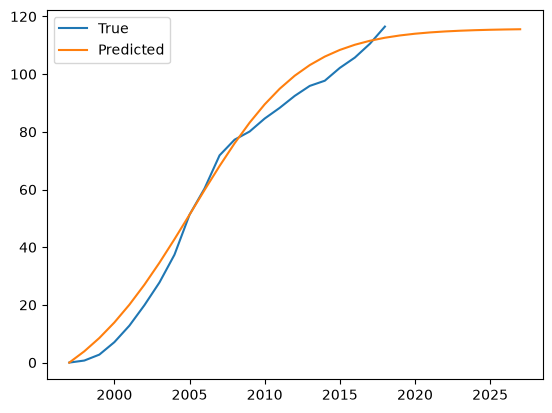

In [32]:
from matplotlib import pyplot as plt

plt.plot(forecast["Cum_Subs"], label="True")
plt.plot(forecast["Pred_Cum_Subs"], label="Predicted")
plt.legend()
plt.show()